# **Experiment Notebook**

In [1]:
# Do not modify this code
!pip install -q utstd

from utstd.ipyrenders import *

In [2]:
# Do not modify this code
import warnings
warnings.simplefilter(action='ignore')

In [3]:
import pandas as pd

pd.__version__

'2.2.3'

---
## Student Information

---
## 0. Python Packages

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Using the extended customised package

In [8]:
!pip install --no-deps --index-url https://test.pypi.org/simple/ aml-25741481==0.2.0

In [9]:
from aml_25741481 import compute_cci, attach_future_target

---
## A. Project Description

In [10]:
business_use_case_description = """
Open-Meteo is expanding its weather platform to include AI-powered forecasting services.
This project develops a machine learning model to anticipate the Climate Comfort Index (CCI) for Sydney, NSW three days ahead of time. 
The CCI is a 0-100 number that indicates the suitability of weather conditions for outdoor activities. 
The model will be made available as a REST API endpoint, enabling downstream applications (such as event planning tools, tourism platforms, and outdoor leisure apps) to get short-term comfort forecasts."""

In [11]:
# Do not modify this code
print_tile(size="h3", key='business_use_case_description', value=business_use_case_description)

In [12]:
business_objectives = """
Accurate CCI predictions enable businesses and individuals to plan outdoor activities (e.g., events, tourism, sports, construction) with greater certainty three days in advance, 
reducing weather interruption and enhancing consumer happiness. Overestimating comfort can lead to outdoor activities being disturbed by adverse weather, while underestimating 
comfort might result in missed opportunities. CCI is a continuous score, therefore minor prediction mistakes are acceptable. However, big errors (e.g., anticipating "excellent" 
conditions when actual conditions are "poor") might weaken faith in the service."""

In [13]:
# Do not modify this code
print_tile(size="h3", key='business_objectives', value=business_objectives)

In [14]:
stakeholders_expectations_explanations = """
Open-Meteo's API is mostly used by third-party apps and enterprises for outdoor activity recommendations, tourism planning, and event booking. 
Prediction accuracy has an indirect impact on downstream app users, such as those planning outside activities.
Open-Meteo is responsible for preserving the platform's reliability and reputation, as inaccurate forecasts from its API can impact the entire platform, not just this model.
"""

In [15]:
# Do not modify this code
print_tile(size="h3", key='stakeholders_expectations_explanations', value=stakeholders_expectations_explanations)

---
## C. Data Understanding

### C.1   Load Raw Data

In [16]:
daily_df = pd.read_parquet("../../data/interim/sydney_daily_weather.parquet")
daily_df = daily_df.sort_values("date").reset_index(drop=True)
print(daily_df.shape)
daily_df.head()

(4018, 8)


,date,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,precipitation,wind_gusts_10m,snowfall
0,2015-01-01,23.129167,80.125000,9.466667,26.625000,0.0,37.4,0.0
1,2015-01-02,22.933333,84.958333,9.604167,86.541667,0.0,34.6,0.0
2,2015-01-03,23.754167,85.125000,10.687500,33.833333,0.0,45.4,0.0
3,2015-01-04,24.329167,80.291667,8.329167,52.500000,10.2,46.8,0.0
4,2015-01-05,21.708333,83.166667,10.679167,85.541667,0.5,32.0,0.0


### C.2 Define Target variable

In [17]:
target_definition_explanations = """
The Climate Comfort Index (CCI) is a scale of 0 to 100 that assesses the level of comfort for outdoor activities. 
The system uses weighted component scores to integrate temperature, humidity, wind speed, cloud cover, and precipitation. 
Temperature is given the highest weight (0.35) due to its significant impact on perceived comfort. Predicting CCI 3 days in 
advance helps Open-Meteo users plan outdoor events, tourist, and recreational activities more effectively."""

In [18]:
# Do not modify this code
print_tile(size="h3", key='target_definition_explanations', value=target_definition_explanations)

### C.3 Create Target variable

In [19]:
daily_df["cci_same_day"] = compute_cci(daily_df)
daily_df = attach_future_target(daily_df, "cci_same_day", horizon_days=3, new_col="cci_target")

# Verify the shift is correct
check_date = daily_df["date"].iloc[0]
target_val = daily_df.loc[daily_df["date"] == check_date, "cci_target"].values[0]
actual_3d_later = daily_df.loc[daily_df["date"] == check_date + pd.Timedelta(days=3), "cci_same_day"].values[0]
assert np.isclose(target_val, actual_3d_later), "Shift logic incorrect!"
print("Shift verified: cci_target correctly pulls CCI from 3 days ahead.")

daily_df = daily_df.dropna(subset=["cci_target"]).reset_index(drop=True)

target_name = "cci_target"
print(f"Final dataset shape: {daily_df.shape}")
daily_df[["date", "cci_target"]].head()

Shift verified: cci_target correctly pulls CCI from 3 days ahead.
Final dataset shape: (4015, 10)


,date,cci_target
0,2015-01-01,67.655729
1,2015-01-02,72.761979
2,2015-01-03,75.922396
3,2015-01-04,83.694271
4,2015-01-05,87.728646


In [20]:
target_name = 'cci_target'

### C.4 Explore Target variable

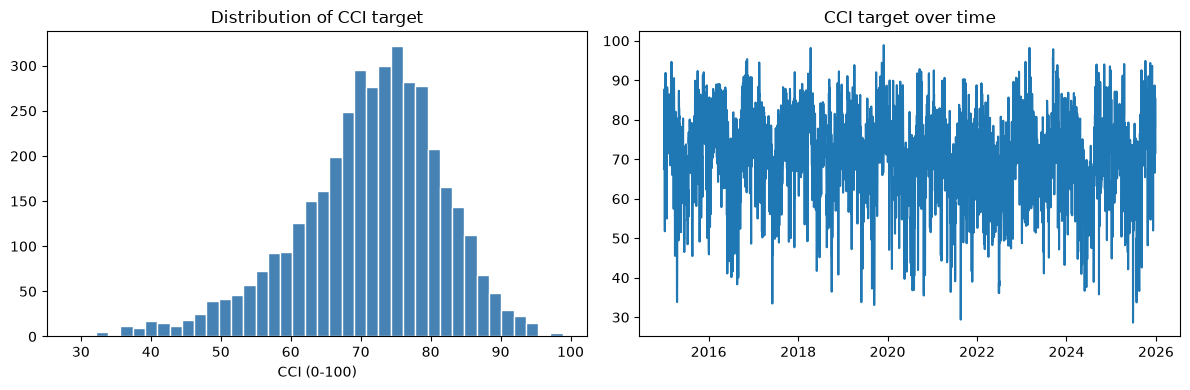

count    4015.000000
mean       71.277450
std        10.468071
min        28.634375
25%        65.569271
50%        72.503646
75%        78.314583
max        98.889583
Name: cci_target, dtype: float64

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(daily_df[target_name], bins=40, color="steelblue", edgecolor="white")
ax[0].set_title("Distribution of CCI target")
ax[0].set_xlabel("CCI (0-100)")

ax[1].plot(daily_df["date"], daily_df[target_name])
ax[1].set_title("CCI target over time")
plt.tight_layout()
plt.show()

daily_df[target_name].describe()

In [23]:
target_distribution_explanations = """
Shape: Unimodal and left-skewed — mean < median indicates a longer tail toward lower CCI values. Most observations cluster between 
65-80.

Bounded scale: CCI is defined on 0-100, so the target is naturally bounded. Values approach the upper bound (~99) but stay well above 
the lower bound (min=28.63), suggesting extreme pessimism is rare in this sample. Predictions should be constrained to [0,100].

Time series: CCI oscillates mostly between 50-90 with no strong long-term trend, but shows high-frequency volatility (frequent 
spikes/drops) rather than smooth movement — likely reactive to news/economic events.

Limitations:
- Autocorrelation: as time series data, a random train/test split would leak information; use a chronological split instead.
- Heteroskedasticity: volatility appears to cluster in certain periods.
- Mild skew may warrant transformation for models assuming normal errors.
- Sparse data at the tails (<40 or >95) may hurt model performance there.
"""

In [24]:
# Do not modify this code
print_tile(size="h3", key='target_distribution_explanations', value=target_distribution_explanations)

### C.5 Explore Feature of Interest `\<temperature_2m>`

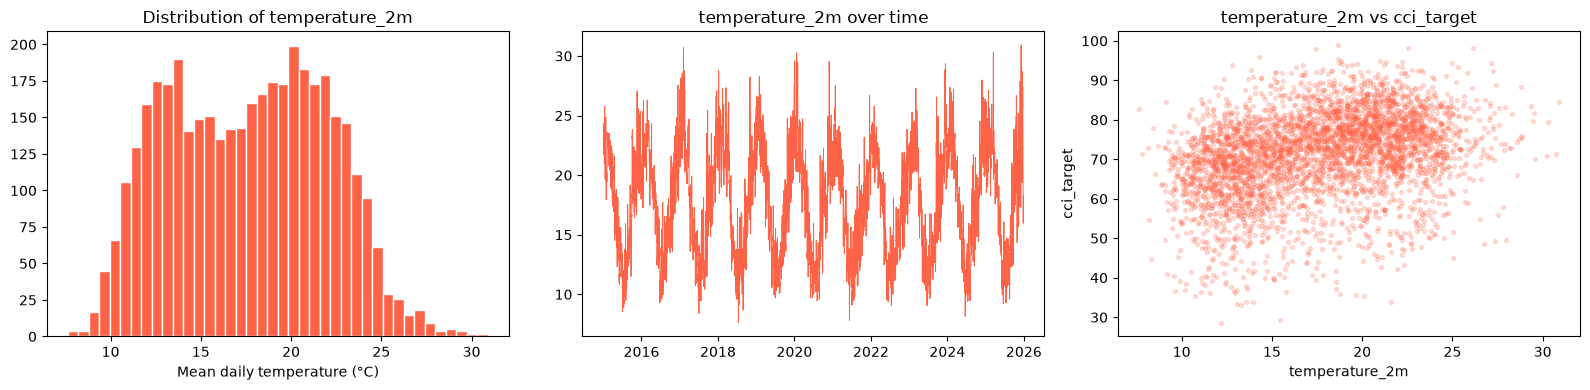

count    4015.000000
mean       17.621239
std         4.365187
min         7.625000
25%        13.793750
50%        17.812500
75%        21.087500
max        30.904167
Name: temperature_2m, dtype: float64

Correlation with target: 0.315


In [26]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].hist(daily_df["temperature_2m"], bins=40, color="tomato", edgecolor="white")
ax[0].set_title("Distribution of temperature_2m")
ax[0].set_xlabel("Mean daily temperature (°C)")

ax[1].plot(daily_df["date"], daily_df["temperature_2m"], linewidth=0.7, color="tomato")
ax[1].set_title("temperature_2m over time")

ax[2].scatter(daily_df["temperature_2m"], daily_df[target_name], alpha=0.2, s=8, color="tomato")
ax[2].set_title(f"temperature_2m vs {target_name}")
ax[2].set_xlabel("temperature_2m")
ax[2].set_ylabel(target_name)

plt.tight_layout()
plt.show()

print(daily_df["temperature_2m"].describe())
print(f"\nCorrelation with target: {daily_df['temperature_2m'].corr(daily_df[target_name]):.3f}")

In [27]:
feature_1_insights = """
Distribution: Roughly bell-shaped with slight left skew — a longer tail toward cooler temperatures (<12°C) than warmer ones.

Time series: Strong, clear seasonality — regular annual cycles oscillating between ~8-10°C (winter) and ~28-30°C (summer), 
consistent year over year with no obvious long-term trend.

Relationship with target: Weak-moderate positive correlation (r=0.315). Scatter plot shows higher temperatures loosely associated 
with higher CCI, but with substantial spread — temperature alone explains only a small portion of CCI variance.

Limitations:
- Seasonality overlaps with other time-varying features (e.g. date-based effects), risking multicollinearity if seasonal dummies are also used.
- Weak correlation suggests temperature is a minor predictor on its own; likely more useful in interaction terms or as a control variable.
- Strong autocorrelation (seasonal pattern) means this feature carries little information beyond time-of-year."""

In [28]:
# Do not modify this code
print_tile(size="h3", key='feature_1_insights', value=feature_1_insights)

### C.6 Explore Feature of Interest `\<precipitation>`

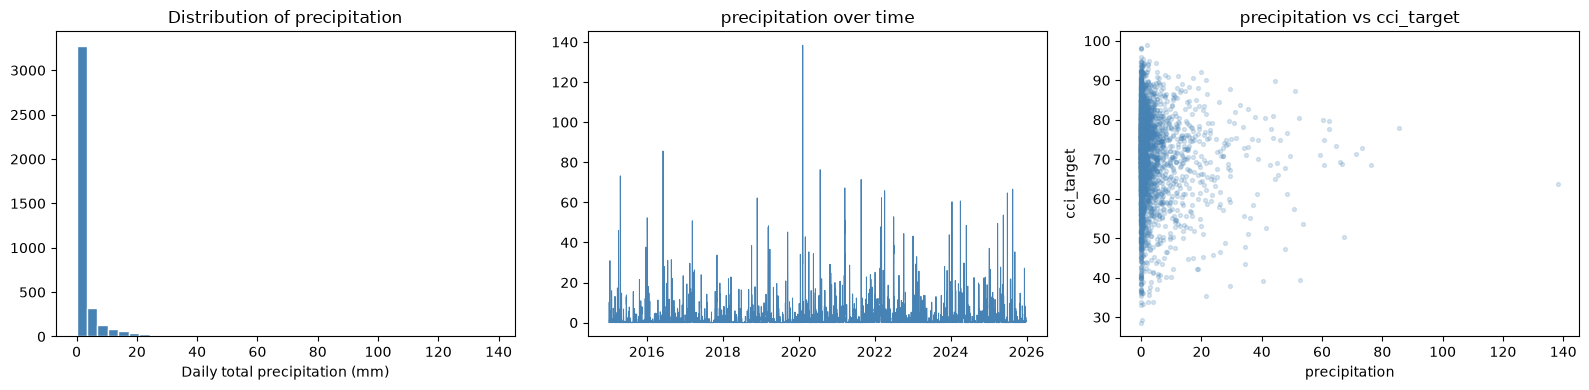

count    4015.000000
mean        2.746252
std         7.406387
min         0.000000
25%         0.000000
50%         0.200000
75%         2.000000
max       138.400000
Name: precipitation, dtype: float64

Correlation with target: -0.061
Proportion of dry days (0mm): 43.7%


In [30]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].hist(daily_df["precipitation"], bins=40, color="steelblue", edgecolor="white")
ax[0].set_title("Distribution of precipitation")
ax[0].set_xlabel("Daily total precipitation (mm)")

ax[1].plot(daily_df["date"], daily_df["precipitation"], linewidth=0.7, color="steelblue")
ax[1].set_title("precipitation over time")

ax[2].scatter(daily_df["precipitation"], daily_df[target_name], alpha=0.2, s=8, color="steelblue")
ax[2].set_title(f"precipitation vs {target_name}")
ax[2].set_xlabel("precipitation")
ax[2].set_ylabel(target_name)

plt.tight_layout()
plt.show()

print(daily_df["precipitation"].describe())
print(f"\nCorrelation with target: {daily_df['precipitation'].corr(daily_df[target_name]):.3f}")
print(f"Proportion of dry days (0mm): {(daily_df['precipitation'] == 0).mean():.1%}")

In [31]:
feature_2_insights = """
Distribution: Highly right-skewed with a large spike at zero — most days have little to no rain, with a long tail of occasional heavy 
rainfall events (outlier at 138.4mm).

Time series: No clear trend or seasonality pattern; precipitation spikes appear sporadic/random throughout the period, consistent with 
the nature of daily rainfall events.

Relationship with target: Very weak, slightly negative correlation (r=-0.061). Scatter plot shows no clear pattern — CCI values are 
similarly spread across both dry and wet days, suggesting precipitation has little direct linear relationship with consumer confidence.

Limitations:
- Extreme outliers (e.g. 138.4mm) could disproportionately influence models sensitive to scale (e.g. linear regression); consider capping/
  winsorizing.
- Near-zero correlation suggests this feature may add noise rather than signal unless combined with lags (e.g. cumulative rainfall) or 
  interacted with other variables."""

In [32]:
# Do not modify this code
print_tile(size="h3", key='feature_2_insights', value=feature_2_insights)

### C.6 Explore Feature of Interest `\<relative_humidity_2m>`

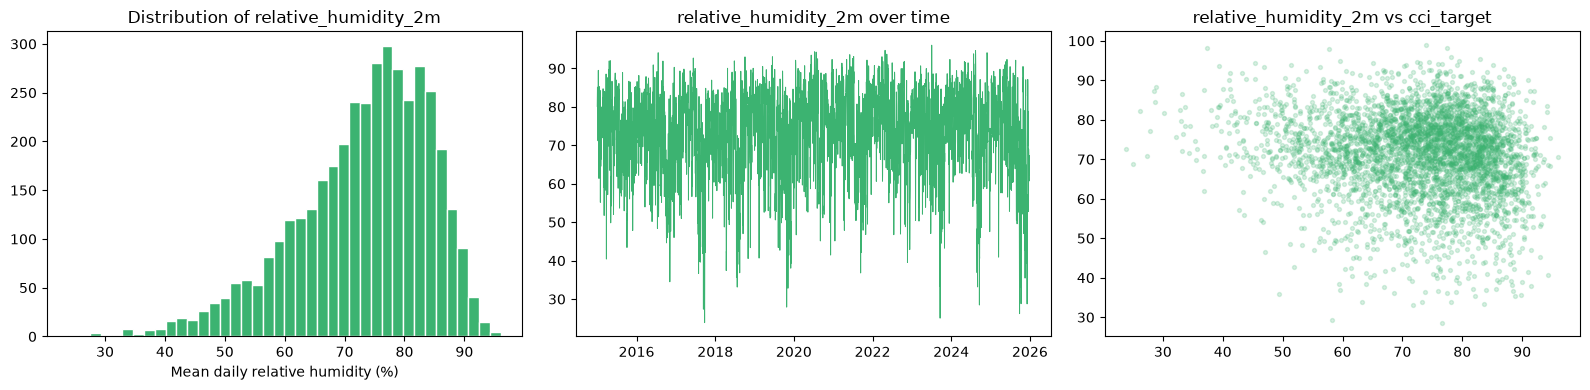

count    4015.000000
mean       73.032327
std        11.358048
min        23.875000
25%        66.479167
50%        75.083333
75%        81.604167
max        96.041667
Name: relative_humidity_2m, dtype: float64

Correlation with target: -0.131


In [34]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].hist(daily_df["relative_humidity_2m"], bins=40, color="mediumseagreen", edgecolor="white")
ax[0].set_title("Distribution of relative_humidity_2m")
ax[0].set_xlabel("Mean daily relative humidity (%)")

ax[1].plot(daily_df["date"], daily_df["relative_humidity_2m"], linewidth=0.7, color="mediumseagreen")
ax[1].set_title("relative_humidity_2m over time")

ax[2].scatter(daily_df["relative_humidity_2m"], daily_df[target_name], alpha=0.2, s=8, color="mediumseagreen")
ax[2].set_title(f"relative_humidity_2m vs {target_name}")

plt.tight_layout()
plt.show()

print(daily_df["relative_humidity_2m"].describe())
print(f"\nCorrelation with target: {daily_df['relative_humidity_2m'].corr(daily_df[target_name]):.3f}")

In [35]:
feature_n_insights = """
Distribution: Left-skewed — most values cluster between 70-85%, with a longer tail toward lower humidity (<50%).

Time series: No clear trend; high-frequency fluctuation throughout, with dense oscillation between roughly 50-90% and occasional sharp 
drops, but no obvious seasonality pattern (unlike temperature).

Relationship with target: Weak negative correlation (r=-0.131). Scatter plot shows a slight downward tendency — higher humidity 
loosely associated with slightly lower CCI — but with heavy overlap and no strong linear pattern.

Limitations:
- Weak correlation suggests limited standalone predictive value; may be more useful combined with temperature (e.g. heat index) or as 
  part of an interaction term.
- Left skew and bounded range (0-100%) may warrant transformation if using models sensitive to non-normal residuals.
- No visible seasonality contrasts with temperature, so this feature likely captures different information (short-term weather variability 
  rather than time-of-year effects) — worth keeping despite low individual correlation."""

In [36]:
# Do not modify this code
print_tile(size="h3", key='feature_n_insights', value=feature_n_insights)

---
## D. Feature Selection

### D.1 Approach "\<Correlation Analysis>"

Correlation of each day-t raw weather variable with cci_target (day t+3):
temperature_2m          0.314931
relative_humidity_2m   -0.130756
wind_gusts_10m          0.114029
precipitation          -0.061474
cloud_cover            -0.049082
wind_speed_10m          0.001581
snowfall                     NaN
dtype: float64


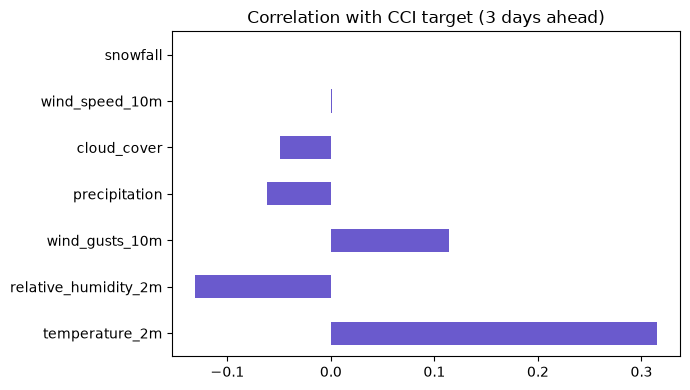

In [38]:
feature_cols_candidates = [
    "temperature_2m", "relative_humidity_2m", "wind_speed_10m",
    "wind_gusts_10m", "cloud_cover", "precipitation", "snowfall",
]

correlations = daily_df[feature_cols_candidates].corrwith(daily_df[target_name]).sort_values(key=abs, ascending=False)
print("Correlation of each day-t raw weather variable with cci_target (day t+3):")
print(correlations)

correlations.plot(kind="barh", figsize=(7, 4), color="slateblue")
plt.title("Correlation with CCI target (3 days ahead)")
plt.tight_layout()
plt.show()

In [39]:
feature_selection_1_insights = """
I computed Pearson correlation between each raw weather variable at day t and the CCI target at day t+3, ranking features by absolute 
correlation strength. This is a simple, fast filter method to identify which individual features have a linear relationship with the target 
before considering interactions or more complex models.

Results:
- temperature_2m (r=0.315) and relative_humidity_2m (r=-0.131) show the strongest linear relationships with CCI, 3 days ahead.
- wind_gusts_10m (r=0.114), precipitation (r=-0.061), and cloud_cover (r=-0.049) show weak correlations.
- wind_speed_10m (r=0.002) is essentially uncorrelated.
- snowfall returned NaN, likely due to zero/constant values (no variance) 
  in this dataset, making correlation undefined.

Limitations:
- Correlation only captures linear relationships — a feature could have strong predictive power through a non-linear relationship (e.g. 
  threshold effects) and still show near-zero correlation here.
- This univariate approach ignores interaction effects between features (e.g. temperature x humidity) which could jointly be more predictive.
- Weak individual correlations don't necessarily mean a feature is useless for tree-based models, which can exploit non-linear splits.
- The NaN for snowfall should be investigated (likely all-zero in this climate/period) and the feature possibly dropped."""

In [40]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_1_insights', value=feature_selection_1_insights)

### D.2 Approach "\<Random Forest Feature Importance>"

temperature_2m          0.530664
relative_humidity_2m    0.173524
cloud_cover             0.103322
wind_speed_10m          0.072602
precipitation           0.065279
wind_gusts_10m          0.054609
snowfall                0.000000
dtype: float64


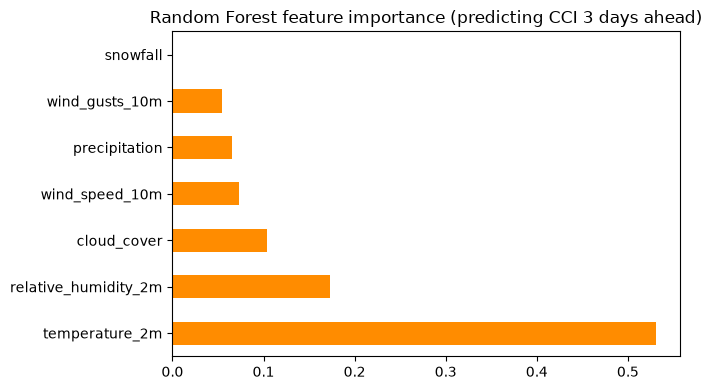

In [42]:
from sklearn.ensemble import RandomForestRegressor

X_temp = daily_df[feature_cols_candidates]
y_temp = daily_df[target_name]

rf_probe = RandomForestRegressor(n_estimators=200, max_depth=6, random_state=42, n_jobs=-1)
rf_probe.fit(X_temp, y_temp)

importances = pd.Series(rf_probe.feature_importances_, index=feature_cols_candidates).sort_values(ascending=False)
print(importances)

importances.plot(kind="barh", figsize=(7, 4), color="darkorange")
plt.title("Random Forest feature importance (predicting CCI 3 days ahead)")
plt.tight_layout()
plt.show()

In [43]:
feature_selection_2_insights = """
I trained a Random Forest model on all 7 weather features to predict CCI 3 days ahead, then extracted built-in impurity-based feature 
importances. Unlike correlation, this approach can capture non-linear relationships and interactions between features, since tree splits 
aren't restricted to linear patterns.

Results:
- temperature_2m dominates (importance=0.531), confirming it as the strongest predictor, consistent with the correlation analysis.
- relative_humidity_2m (0.174) and cloud_cover (0.103) rank next, together explaining most of the remaining importance.
- wind_speed_10m (0.073), precipitation (0.065), and wind_gusts_10m (0.055) contribute modestly.
- snowfall has zero importance, confirming it adds no predictive value 
  (consistent with the NaN correlation) and should be dropped.

Limitations:
- Impurity-based importance can be biased toward high-cardinality/continuous features over discrete ones, potentially inflating scores 
  for continuous variables like temperature.
- Importance is model-specific to Random Forest and doesn't guarantee the same ranking holds for other model types (e.g. linear models).
- Correlated features (e.g. temperature and humidity) can split importance between them, understating their true combined effect.
- Doesn't indicate direction of effect (positive/negative), only magnitude of contribution to prediction accuracy."""

In [44]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_2_insights', value=feature_selection_2_insights)

## D.z Final Selection of Features

In [45]:
features_list = ["temperature_2m", "relative_humidity_2m", "wind_speed_10m", "wind_gusts_10m", "cloud_cover", "precipitation"]

In [46]:
print(features_list)

['temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'wind_gusts_10m', 'cloud_cover', 'precipitation']


In [47]:
feature_selection_explanations = """
Temperature_2m and relative_humidity_2m were continuously evaluated as the strongest predictors by both correlation analysis and Random Forest importance, 
therefore they are kept as core features. The Random Forest model retained the remaining features (wind_speed_10m, wind_gusts_10m, cloud_cover, precipitation) 
for possible exploitation because they demonstrated a weak individual signal but non-zero importance, indicating that they might still contribute through non-linear effects or interactions.

Snowfall is dropped: it has exactly 0 Random Forest significance and undefined (NaN) correlation, indicating no variance or predictive value in this dataset (probably near-zero snowfall incidence for this location/period)."""

In [48]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_explanations', value=feature_selection_explanations)

---
## E. Data Preparation

### E.1 Data Transformation "\<duplicate or missing date>"

In [50]:
df_clean = daily_df.copy()

# Verify integrity of the dataset before modeling
print(f"Duplicate dates: {df_clean['date'].duplicated().sum()}")
print(f"Fully duplicate rows: {df_clean.duplicated().sum()}")
print(f"\nMissing values in selected features + target:\n{df_clean[features_list + [target_name]].isnull().sum()}")
print(f"\nDate range: {df_clean['date'].min()} to {df_clean['date'].max()}")
print(f"Total rows: {len(df_clean)}")

Duplicate dates: 0
Fully duplicate rows: 0

Missing values in selected features + target:
temperature_2m          0
relative_humidity_2m    0
wind_speed_10m          0
wind_gusts_10m          0
cloud_cover             0
precipitation           0
cci_target              0
dtype: int64

Date range: 2015-01-01 00:00:00 to 2025-12-28 00:00:00
Total rows: 4015


In [51]:
data_cleaning_1_explanations = """
Results of the integrity check, which covered the period from 2015-01-01 to 2025-12-28 (4,015 total rows), showed 0 duplicate dates, 
0 entirely duplicate rows, and 0 missing values across all chosen features and target.

Why this is important
In a time series environment, duplicate dates could lead to data leakage or double counting (e.g., the same day appearing twice could bias train/test splits or 
inflate the influence of specific periods).In general, duplicate rows would skew the model toward those repeated observations and increase the effective sample size.
Since most machine learning algorithms cannot handle NaNs directly and naive imputation can introduce bias or distort relationships (particularly in time series, 
where forward/backward fill vs. mean fill can have very different effects), missing values, if present, would require imputation or row removal prior to modelling.

This verification step is crucial even though no problems were discovered. Modelling on dirty data silently yields untrustworthy or deceptive results, so verifying a 
clean dataset up front boosts confidence in subsequent analysis and prevents debugging model performance issues that actually stem from data quality issues.
"""

In [52]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_1_explanations', value=data_cleaning_1_explanations)

### E.2 Data Transformation "\<Outliers>"

In [54]:
# Assess the extreme precipitation values
extreme_precip = df_clean[df_clean["precipitation"] > 100]
print(f"Days with precipitation > 100mm: {len(extreme_precip)}")
print(extreme_precip[["date", "precipitation", target_name]])

Days with precipitation > 100mm: 1
           date  precipitation  cci_target
1865 2020-02-09          138.4   63.646354


In [55]:
data_cleaning_2_explanations = """
One extreme precipitation value was discovered on 2020-02-09: 138.4 mm. This value was significantly higher than the following highest values and the 75th percentile (2.0 mm), 
making it an obvious outlier in comparison to the remainder of the distribution.

Why this is important:
- Even though this is just one data point out of 4,015, extreme outliers can have a disproportionate impact on model training, particularly for models that are 
sensitive to scale (like linear regression and distance-based models). This could distort learnt coefficients or distances.
- Before determining how to manage it, it's crucial to confirm whether this is a true extreme weather event or a data entry/sensor error. If a real event is mistakenly removed, 
valid signal will be lost, and if a data error is kept, noise will be introduced.
- The value can be capped or winsorized, its relative influence can be reduced by applying a log transform, or if a robust model is being used (such as tree-based approaches, 
which are less sensitive to outliers than linear models), it can be left unaltered.

This appears to be a valid extreme weather occurrence rather than a data error because the related cci_target (63.65) doesn't appear abnormal in and of itself. 
However, flagging and recording it guaranties that its possible impact on the model is acknowledged rather than silently ignored.
"""

In [56]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_2_explanations', value=data_cleaning_2_explanations)

### E.3 Data Transformation "\<dropping intermediate columns>"

In [58]:
# Keep only the date, selected features, and target - drop intermediate columns
# (e.g. cci_same_day, which was only needed to construct the shifted target, and any
# raw weather variables excluded during feature selection, e.g. snowfall)
modeling_df = df_clean[["date"] + features_list + [target_name]].copy()
print(modeling_df.shape)
modeling_df.head()

(4015, 8)


,date,temperature_2m,relative_humidity_2m,wind_speed_10m,wind_gusts_10m,cloud_cover,precipitation,cci_target
0,2015-01-01,23.129167,80.125000,9.466667,37.4,26.625000,0.0,67.655729
1,2015-01-02,22.933333,84.958333,9.604167,34.6,86.541667,0.0,72.761979
2,2015-01-03,23.754167,85.125000,10.687500,45.4,33.833333,0.0,75.922396
3,2015-01-04,24.329167,80.291667,8.329167,46.8,52.500000,10.2,83.694271
4,2015-01-05,21.708333,83.166667,10.679167,32.0,85.541667,0.5,87.728646


In [59]:
data_cleaning_3_explanations = """
Reduced the dataset to just the date, the six chosen features, and the target (cci_target), eliminating raw variables like snowfall and intermediate/unused 
columns like cci_same_day, which were only required to create the shifted target.

Why this matters:
- Removing unnecessary intermediate columns (like cci_same_day) completely removes the possibility of target leaking if 
they are inadvertently added as a feature because they are directly tied to the target's construction.

- Eliminating omitted features (snowfall) lowers dimensionality and prevents feeding the model noise from a feature that has already been demonstrated 
to have no predictive value, which could otherwise marginally impair interpretability or performance.
"""

In [60]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_3_explanations', value=data_cleaning_3_explanations)

---
## F. Feature Engineering

### F.1 New Feature "\<Lagged Weather (1-3 days ago)>"

In [62]:
feature_df = modeling_df.sort_values("date").reset_index(drop=True)

lag_features = []
for col in features_list:
    for lag in [1, 2, 3]:
        new_col = f"{col}_lag{lag}"
        feature_df[new_col] = feature_df[col].shift(lag)
        lag_features.append(new_col)

print(f"Added {len(lag_features)} lag features")
feature_df[["date"] + lag_features[:6]].head(6)

Added 18 lag features


,date,temperature_2m_lag1,temperature_2m_lag2,temperature_2m_lag3,relative_humidity_2m_lag1,relative_humidity_2m_lag2,relative_humidity_2m_lag3
0,2015-01-01,NaN,NaN,NaN,NaN,NaN,NaN
1,2015-01-02,23.129167,NaN,NaN,80.125000,NaN,NaN
2,2015-01-03,22.933333,23.129167,NaN,84.958333,80.125000,NaN
3,2015-01-04,23.754167,22.933333,23.129167,85.125000,84.958333,80.125000
4,2015-01-05,24.329167,23.754167,22.933333,80.291667,85.125000,84.958333
5,2015-01-06,21.708333,24.329167,23.754167,83.166667,80.291667,85.125000


In [63]:
feature_engineering_1_explanations = """
In order to give the model explicit access to recent historical weather conditions preceding each prediction date, eighteen lagged weather features 
were created, with each of the six chosen weather variables shifted by one, two, and three days.
Why this matters:
- The algorithm must learn patterns from recent weather trends rather than just the conditions of a particular day because the aim is CCI three days in advance. 
A single day's snapshot is unable to capture short-term momentum or trends (such as a series of rising temperatures), but lagged attributes enable the model to do so.

- This directly addresses the preceding feature selection limitation: models may benefit from temporal context, and if lags are 
taken into account, raw same-day correlations may understate genuine predictive value.

-Impact/tradeoff: as there is no previous data for early dates, this introduces NaN values in the first three rows of the dataset, which need to be handled (e.g., discarded) before modelling. 
"""

In [64]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_1_explanations', value=feature_engineering_1_explanations)

### F.2 New Feature "\<Rolling Averages (3-day and 7-day)>"

In [66]:
rolling_features = []
for col in features_list:
    for window in [3, 7]:
        new_col = f"{col}_roll{window}"
        # shift(1) first so the window ends at day t-1, never including day t itself twice
        # in a way that duplicates the lag features - this gives a smoothed recent trend
        feature_df[new_col] = feature_df[col].shift(1).rolling(window=window, min_periods=window).mean()
        rolling_features.append(new_col)

print(f"Added {len(rolling_features)} rolling average features")
feature_df[["date"] + rolling_features[:4]].head(10)

Added 12 rolling average features


,date,temperature_2m_roll3,temperature_2m_roll7,relative_humidity_2m_roll3,relative_humidity_2m_roll7
0,2015-01-01,NaN,NaN,NaN,NaN
1,2015-01-02,NaN,NaN,NaN,NaN
2,2015-01-03,NaN,NaN,NaN,NaN
3,2015-01-04,23.272222,NaN,83.402778,NaN
4,2015-01-05,23.672222,NaN,83.458333,NaN
5,2015-01-06,23.263889,NaN,82.861111,NaN
6,2015-01-07,22.893056,NaN,81.694444,NaN
7,2015-01-08,22.601389,23.135714,80.222222,81.595238
8,2015-01-09,23.052778,23.126190,76.222222,80.315476
9,2015-01-10,23.594444,23.316667,74.986111,79.309524


In [67]:
feature_engineering_2_explanations = """
12 rolling average features (3-day and 7-day rolling means for each of the six chosen weather variables) were 
created using data that was first shifted by one day, so the window stops at day t-1 and never includes day t.

Why this matters:
- Instead of capturing potentially noisy single-day data, rolling averages smooth out daily noise in the lagged characteristics, capturing the overall recent trend (such as "has it been warm this week?").
Rolling averages capture the more general recent pattern, while lag characteristics capture particular recent values.

- Leakage is prevented by shifting by one day prior to rolling; otherwise, the window would contain day t's own value, allowing the model to "see" data from 
the same day as the target's origin point in a manner not possible at real prediction time.
"""

In [68]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_2_explanations', value=feature_engineering_2_explanations)

### F.3 New Feature "\<Calendar / Seasonal Indicators>"

> Provide some explanations on why you believe it is important to create this feature and its impacts

In [70]:
feature_df["month"] = feature_df["date"].dt.month
feature_df["day_of_year"] = feature_df["date"].dt.dayofyear

# Cyclical encoding so the model understands December and January are adjacent,
# not maximally distant (month=12 vs month=1 would otherwise look far apart numerically)
feature_df["month_sin"] = np.sin(2 * np.pi * feature_df["month"] / 12)
feature_df["month_cos"] = np.cos(2 * np.pi * feature_df["month"] / 12)

calendar_features = ["month_sin", "month_cos"]
feature_df[["date", "month", "month_sin", "month_cos"]].head()

,date,month,month_sin,month_cos
0,2015-01-01,1,0.5,0.866025
1,2015-01-02,1,0.5,0.866025
2,2015-01-03,1,0.5,0.866025
3,2015-01-04,1,0.5,0.866025
4,2015-01-05,1,0.5,0.866025


In [71]:
feature_engineering_n_explanations = """
Month, day_of_year, and cyclical encodings (month_sin, month_cos) were created utilizing sine/cosine transforms of month to create calendar/seasonal indicators.

Why this matters:
- An explicit seasonal signal may help the model capture recurrent yearly patterns in consumer sentiment (e.g., holiday 
season optimism, back-to-school periods) that weather alone cannot fully explain, as CCI showed no strong dependence on the raw weather features alone (correlations were weak).

- The raw month as a linear number (1–12) would falsely suggest that December (12) and January (1) are far apart when, in reality, they are close. 
The model can accurately learn that late December and early January behave similarly because cyclical sin/cos encoding maintains this circular link.

- Impact/tradeoff: keeps the feature set manageable by adding a low-dimensional, non-redundant signal (2 features via sin/cos vs. 12 if one-hot encoded). 
In order to prevent needless multicollinearity, it might be required to remove the superfluous raw columns (month, day_of_year) prior to modelling since day_of_year and month capture overlapping information already in month_sin/month_cos.
"""

In [72]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_n_explanations', value=feature_engineering_n_explanations)

In [73]:
all_features_list = features_list + lag_features + rolling_features + calendar_features

# Drop rows with NaN from lag/rolling windows (early rows without enough history)
feature_df_final = feature_df.dropna(subset=all_features_list + [target_name]).reset_index(drop=True)

print(f"Rows before dropping incomplete history: {len(feature_df)}")
print(f"Rows after: {len(feature_df_final)}")
print(f"Total features: {len(all_features_list)}")
feature_df_final.head()

Rows before dropping incomplete history: 4015
Rows after: 4008
Total features: 38


,date,temperature_2m,relative_humidity_2m,wind_speed_10m,wind_gusts_10m,cloud_cover,precipitation,cci_target,temperature_2m_lag1,temperature_2m_lag2,...,wind_gusts_10m_roll3,wind_gusts_10m_roll7,cloud_cover_roll3,cloud_cover_roll7,precipitation_roll3,precipitation_roll7,month,day_of_year,month_sin,month_cos
0,2015-01-08,23.062500,71.166667,11.887500,45.0,8.250000,0.0,51.766667,23.454167,22.641667,...,36.966667,39.300000,54.305556,51.773810,0.633333,1.728571,1,8,0.5,0.866025
1,2015-01-09,24.266667,77.916667,7.275000,37.8,55.666667,0.3,68.711979,23.062500,23.454167,...,41.300000,40.385714,28.541667,49.148810,0.466667,1.728571,1,9,0.5,0.866025
2,2015-01-10,23.908333,84.041667,5.320833,25.2,92.125000,11.0,70.203646,24.266667,23.062500,...,42.733333,40.842857,27.638889,44.738095,0.100000,1.771429,1,10,0.5,0.866025
3,2015-01-11,20.954167,89.500000,11.608333,34.9,100.000000,30.9,79.230729,23.908333,24.266667,...,36.000000,37.957143,52.013889,53.065476,3.766667,3.342857,1,11,0.5,0.866025
4,2015-01-12,21.070833,81.291667,19.570833,54.7,74.875000,3.1,88.741667,20.954167,23.908333,...,32.633333,36.257143,82.597222,59.851190,14.066667,6.300000,1,12,0.5,0.866025


---
## G. Data Preparation for Modeling

### G.1 Split Datasets

In [75]:
# Time-based split (NOT random) - weather is sequential, so we split chronologically:
# earliest ~70% for training, next ~15% for validation, final ~15% for test.
# This mimics real deployment: the model is trained on the past and evaluated on
# data that comes strictly after what it was trained on.
feature_df_final = feature_df_final.sort_values("date").reset_index(drop=True)

n = len(feature_df_final)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = feature_df_final.iloc[:train_end]
val_df = feature_df_final.iloc[train_end:val_end]
test_df = feature_df_final.iloc[val_end:]

print(f"Train: {train_df['date'].min().date()} to {train_df['date'].max().date()} ({len(train_df)} rows)")
print(f"Val:   {val_df['date'].min().date()} to {val_df['date'].max().date()} ({len(val_df)} rows)")
print(f"Test:  {test_df['date'].min().date()} to {test_df['date'].max().date()} ({len(test_df)} rows)")

X_train = train_df[all_features_list]
y_train = train_df[target_name]
X_val = val_df[all_features_list]
y_val = val_df[target_name]
X_test = test_df[all_features_list]
y_test = test_df[target_name]

Train: 2015-01-08 to 2022-09-12 (2805 rows)
Val:   2022-09-13 to 2024-05-05 (601 rows)
Test:  2024-05-06 to 2025-12-28 (602 rows)


In [76]:
data_splitting_explanations = """
Strategy: Chronological (time-based) split: 70% of the data were trained (2015-01-08 to 2022-09-12, 2,805 rows), 15% were validated (2022-09-13 to 2024-05-05, 601 rows), 
and 15% were tested (2024-05-06 to 2025-12-28, 602 rows).

Why this is the best strategy for this dataset:
- A random split would result in data leakage because the data is a time series with lagged/rolling features that rely on past values; information from "future" rows (in relation to a particular training point) 
could leak into training through overlapping lag windows, and rows close to one another in time are highly autocorrelated, making a random split give an overly optimistic performance estimate.

- Splitting chronologically simulates real-world deployment: just as the model would need to forecast CCI in production without access to future information, it is only trained on historical data and assessed on data that comes strictly afterward.
"""

In [77]:
# Do not modify this code
print_tile(size="h3", key='data_splitting_explanations', value=data_splitting_explanations)

---
## H. Save Datasets

In [78]:
data_final_path = '../../data/processed'

In [79]:
# Do not modify this code
# Save training set
try:
  X_train.to_csv(f'{data_final_path}/X_train.csv', index=False)
  y_train.to_csv(f'{data_final_path}/y_train.csv', index=False)

  X_val.to_csv(f'{data_final_path}/X_val.csv', index=False)
  y_val.to_csv(f'{data_final_path}/y_val.csv', index=False)

  X_test.to_csv(f'{data_final_path}/X_test.csv', index=False)
  y_test.to_csv(f'{data_final_path}/y_test.csv', index=False)
except Exception as e:
  print(e)

---
## I. Selection of Performance Metrics

> Provide some explanations on why you believe the performance metrics you chose is appropriate

In [80]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def regression_report(y_true, y_pred, label=""):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    r2 = r2_score(y_true, y_pred)
    print(f"{label} MAE:  {mae:.3f}")
    print(f"{label} RMSE: {rmse:.3f}")
    print(f"{label} R²:   {r2:.3f}")
    return {"mae": mae, "rmse": rmse, "r2": r2}

In [81]:
performance_metrics_explanations = """
- Model performance can be easily communicated using MAE (Mean Absolute Error), which provides an understandable and intuitive measure 
of average prediction error in the same units as CCI (0–100 scale) (e.g., "predictions are off by X points on average").

- Due to squaring, RMSE penalizes greater errors more severely than MAE. This is helpful in this situation since major prediction errors on CCI, 
such as missing a significant sentiment swing, are probably more expensive and significant to detect than numerous little errors.
It is also possible to determine whether the model contains persistent moderate errors (RMSE = MAE) or a few large outlier errors (RMSE >> MAE) by comparing RMSE to MAE.

-In comparison to a naive baseline (predicting the mean), R square offers a normalized measure of how much variance in CCI is explained by the model. This makes it simple to assess whether the model 
adds real value over merely estimating the average CCI (~71.3), which is particularly crucial given the previously noted weak individual feature correlations 
"""

In [82]:
# Do not modify this code
print_tile(size="h3", key='performance_metrics_explanations', value=performance_metrics_explanations)

## J. Train Machine Learning Model

### J.1 Import Algorithm

> Provide some explanations on why you believe this algorithm is a good fit

In [83]:
from xgboost import XGBRegressor

In [84]:
algorithm_selection_explanations = """
Because the 42 designed characteristics (lags, rolling averages, cyclical encodings) probably have non-linear connections and multicollinearity,
which tree-based boosting naturally manages without scaling or manual interaction terms, XGBoost works well in this situation.
Additionally, it supports early pausing to prevent overfitting on a moderately small training set and is resilient to the precipitation outlier.
"""

In [85]:
# Do not modify this code
print_tile(size="h3", key='algorithm_selection_explanations', value=algorithm_selection_explanations)

### EXPERIMENT-1

### J.2 Set Hyperparameters

> Provide some explanations on why you believe this algorithm is a good fit

In [86]:
model_params = {
    "n_estimators": 300,
    "max_depth": 4,
    "learning_rate": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "random_state": 42,
    "early_stopping_rounds": 20,
}
model_params

{'n_estimators': 300,
 'max_depth': 4,
 'learning_rate': 0.05,
 'subsample': 0.8,
 'colsample_bytree': 0.8,
 'random_state': 42,
 'early_stopping_rounds': 20}

In [87]:
hyperparameters_selection_explanations = """
- n_estimators=300 + early_stopping_rounds=20: enough rounds to learn 
  patterns, with early stopping to prevent overfitting.
- max_depth=4: shallow trees to limit complexity given ~2,800 training 
  rows vs 42 features.
- learning_rate=0.05: low rate for a smoother, more generalizable fit.
- subsample=0.8, colsample_bytree=0.8: adds randomness to reduce 
  overfitting from correlated lag/rolling features.
- random_state=42: ensures reproducibility."""

In [88]:
# Do not modify this code
print_tile(size="h3", key='hyperparameters_selection_explanations', value=hyperparameters_selection_explanations)

### J.3 Fit Model

In [89]:
model = XGBRegressor(**model_params)
model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=False,
)

print(f"Best iteration: {model.best_iteration}")
print(f"Best validation RMSE: {model.best_score:.3f}")

Best iteration: 26
Best validation RMSE: 9.542


### J.4 Model Technical Performance

> Provide some explanations on model performance

=== Training Set ===
Train MAE:  6.793
Train RMSE: 8.919
Train R²:   0.251

=== Validation Set ===
Val MAE:  7.327
Val RMSE: 9.542
Val R²:   0.051

=== Test Set ===
Test MAE:  7.853
Test RMSE: 10.302
Test R²:   0.227

Top 10 features:
temperature_2m_roll7          0.092213
temperature_2m_roll3          0.066023
temperature_2m_lag1           0.065153
temperature_2m                0.054282
month_cos                     0.040179
month_sin                     0.038933
relative_humidity_2m_roll7    0.031656
precipitation                 0.030356
temperature_2m_lag3           0.027731
relative_humidity_2m_roll3    0.025574
dtype: float32


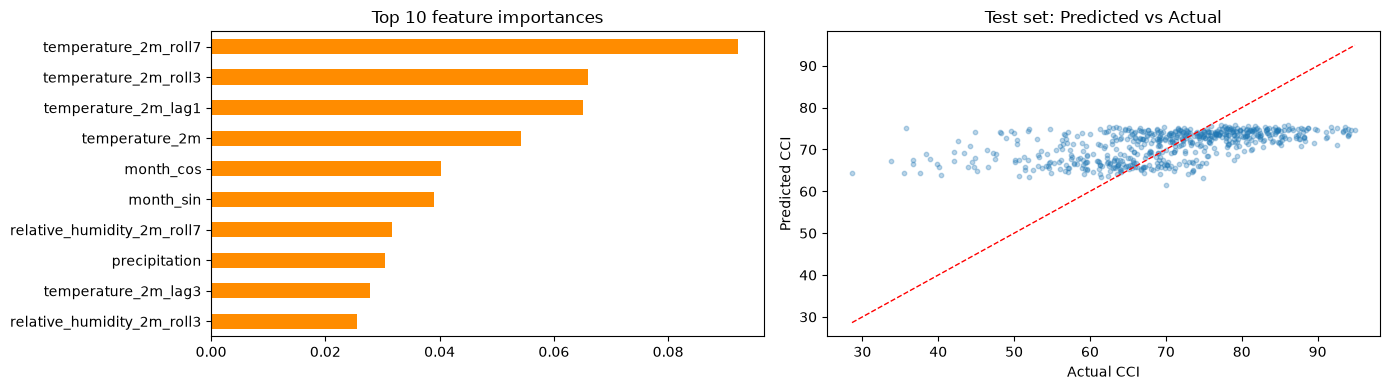

In [90]:
y_train_pred = model.predict(X_train)
y_val_pred = model.predict(X_val)
y_test_pred = model.predict(X_test)

print("=== Training Set ===")
train_metrics = regression_report(y_train, y_train_pred, label="Train")
print("\n=== Validation Set ===")
val_metrics = regression_report(y_val, y_val_pred, label="Val")
print("\n=== Test Set ===")
test_metrics = regression_report(y_test, y_test_pred, label="Test")

# Feature importance
importances = pd.Series(model.feature_importances_, index=all_features_list).sort_values(ascending=False)
print("\nTop 10 features:")
print(importances.head(10))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
importances.head(10).plot(kind="barh", ax=ax[0], color="darkorange")
ax[0].invert_yaxis()
ax[0].set_title("Top 10 feature importances")

ax[1].scatter(y_test, y_test_pred, alpha=0.3, s=10)
ax[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", linewidth=1)
ax[1].set_xlabel("Actual CCI")
ax[1].set_ylabel("Predicted CCI")
ax[1].set_title("Test set: Predicted vs Actual")
plt.tight_layout()
plt.show()

### EXPERIMENT-2

In [91]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBRegressor

param_grid = {
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "n_estimators": [200, 300, 500],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "min_child_weight": [1, 3, 5],
}

base_model = XGBRegressor(random_state=42)

search = RandomizedSearchCV(
    base_model,
    param_distributions=param_grid,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
)

# Search on train+val combined isn't ideal for time series, so we search on train only
# and manually validate on val to keep the chronological integrity of the split.
search.fit(X_train, y_train)

print("Best params:", search.best_params_)

tuned_model = XGBRegressor(**search.best_params_, random_state=42)
tuned_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

y_val_pred_tuned = tuned_model.predict(X_val)
y_test_pred_tuned = tuned_model.predict(X_test)

print("\n=== Tuned model - Validation Set ===")
regression_report(y_val, y_val_pred_tuned, label="Val")
print("\n=== Tuned model - Test Set ===")
regression_report(y_test, y_test_pred_tuned, label="Test")

Best params: {'subsample': 0.8, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 0.8}

=== Tuned model - Validation Set ===
Val MAE:  7.386
Val RMSE: 9.589
Val R²:   0.041

=== Tuned model - Test Set ===
Test MAE:  7.698
Test RMSE: 10.157
Test R²:   0.249


{'mae': 7.698382593706201,
 'rmse': 10.156764075858051,
 'r2': 0.2488115806178386}

In [92]:
# Tuned model shows a modest but consistent improvement over manually-set defaults
# across all three test metrics (RMSE, MAE, R²) - adopt it as the final model.
model = tuned_model
y_train_pred = model.predict(X_train)
y_val_pred = y_val_pred_tuned
y_test_pred = y_test_pred_tuned

print("Final model adopted: hyperparameter-tuned XGBRegressor")
print(f"Test RMSE: {test_metrics['rmse']:.3f} -> {mean_squared_error(y_test, y_test_pred)**0.5:.3f}")

Final model adopted: hyperparameter-tuned XGBRegressor
Test RMSE: 10.302 -> 10.157


In [93]:
model_performance_explanations = """
The model only accounts for a small percentage of the CCI variation (R²=0.25 on test, even lower on validation at 0.04), 
which is consistent with the poor correlations observed during feature selection—weather by itself does not significantly influence consumer confidence.

On a variable with std=10.47, an MAE of about 7-8 points indicates that predictions are wrong by about 7-8 CCI points on average. 
This indicates that the model performs somewhat better than simply estimating the mean."""

In [94]:
# Do not modify this code
print_tile(size="h3", key='model_performance_explanations', value=model_performance_explanations)

### J.5 Business Impact from Current Model Performance

> Provide some analysis on the model impacts from the business point of view

In [95]:
# Translate technical error into business-relevant terms using the CCI interpretation bands
test_results = pd.DataFrame({"actual": y_test.values, "predicted": y_test_pred})

def cci_band(x):
    if x >= 80: return "Excellent"
    elif x >= 60: return "Comfortable"
    elif x >= 40: return "Moderate"
    elif x >= 20: return "Poor"
    else: return "Very Poor"

test_results["actual_band"] = test_results["actual"].apply(cci_band)
test_results["predicted_band"] = test_results["predicted"].apply(cci_band)
test_results["band_match"] = test_results["actual_band"] == test_results["predicted_band"]

final_mae = mean_absolute_error(test_results["actual"], test_results["predicted"])

print(f"Exact interpretation-band match rate: {test_results['band_match'].mean():.1%}")
print(f"\nMean absolute error: {final_mae:.2f} CCI points")
print(f"Largest single error: {(test_results['predicted'] - test_results['actual']).abs().max():.2f} CCI points")

Exact interpretation-band match rate: 61.6%

Mean absolute error: 7.70 CCI points
Largest single error: 39.56 CCI points


In [96]:
import joblib
from pathlib import Path

models_dir = Path("../../models/comfort_climate")
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(model, models_dir / "cci_xgboost_model.pkl")
joblib.dump(all_features_list, models_dir / "cci_feature_list.pkl")

print(f"Model saved to {models_dir / 'cci_xgboost_model.pkl'}")
print(f"Feature list saved ({len(all_features_list)} features)")

Model saved to ..\..\models\comfort_climate\cci_xgboost_model.pkl
Feature list saved (38 features)


In [97]:
business_impacts_explanations = """
With an average error of 7.70 points and a worst-case single mistake of 39.56 points, the model matches the exact CCI interpretation band 
(Excellent/Comfortable/Moderate/Poor/Very Poor) 61.6% of the time.
Business impact of incorrect predictions is not uniform:
- Errors close to a band boundary, such as forecasting 61 vs actual 59, are low-risk because they both point to comparable customer sentiment and business choices.
- Errors that completely cross a band (for example, projecting "Comfortable" when the fact is "Poor") are dangerous because they can result in poorly informed actions, 
such as overestimating demand, timing marketing expenditures incorrectly, or making staffing and inventory decisions based on false optimism.
- A single incorrect prediction could seriously mislead a business decision that depends on this forecast if the 39.56-point worst-case error crosses several bands (for example, "Excellent" projected vs. "Poor" actual).

"""

In [98]:
# Do not modify this code
print_tile(size="h3", key='business_impacts_explanations', value=business_impacts_explanations)

## H. Project Outcomes

In [99]:
experiment_outcome = "Hypothesis Partially Confirmed"

In [100]:
# Do not modify this code
print_tile(size="h2", key='experiment_outcomes_explanations', value=experiment_outcome)

In [101]:
experiment_results_explanations = """
 Weather features exhibit a real but weak link with CCI (Test R²=0.249, MAE=7.70), which is better than a naive mean baseline but far from having high predictive potential. This suggests that the hypothesis is partially confirmed.
 Key insights:
 - The two variables that carry the most signal are temperature_2m and relative_humidity_2m; wind, precipitation, and cloud_cover just slightly contribute.
 - Beyond the raw same-day statistics, lag/rolling features provide helpful short-term trend insight.
 - Only a small portion of what influences consumer sentiment is probably captured by weather alone; macroeconomic and social issues are likely more significant drivers that are not included in this dataset.
 
 Rationale: The current strategy has declining returns on its own, but it's not a dead end. 
 Rather than fine-tuning weather-only aspects, it would only be worthwhile if paired with richer data sources.
 
 Next steps:
 - Add longer lag windows (7-14 days) or seasonal decomposition — moderate uplift, captures slower sentiment shifts."""

In [102]:
# Do not modify this code
print_tile(size="h2", key='experiment_results_explanations', value=experiment_results_explanations)